# Import the Dependencies


In [21]:
import numpy as np                                #numpy arrays---data & mathematical calculation
import pandas as pd                               # dataset frame--- data manipulation
import os                                         #allows to jump on directories, check file/folder existence
from re import search                             #  used to search for patterns in strings.
import shutil                                     # to copy, move, or delete files and directories
import natsort                                    #  sort filenames in a more human-readable way
from PIL import Image                              # opening, manipulating, and saving image files
import matplotlib.pyplot as plt                  # creating visualizations and plots in Python

from tqdm import tqdm                            #A library for adding progress bars to loops.
import cv2                                        #image process


In [2]:
 pip install tensorflow                   #It provides tools for constructing and training neural networks, 

Note: you may need to restart the kernel to use updated packages.


In [22]:
DIR=r'C:\Users\HP\Downloads\Plant leaf(sem6)\images'           #installed and fetching data

In [23]:
train=pd.read_csv(r"C:\Users\HP\Downloads\Plant leaf(sem6)\train.csv")
test=pd.read_csv(r"C:\Users\HP\Downloads\Plant leaf(sem6)\test.csv")

In [24]:
train.head()

,image_id,healthy,multiple_diseases,rust,scab
0,Train_0,0,0,0,1
1,Train_1,0,1,0,0
2,Train_2,1,0,0,0
3,Train_3,0,0,1,0
4,Train_4,1,0,0,0


In [25]:
test.head()

,image_id
0,Test_0
1,Test_1
2,Test_2
3,Test_3
4,Test_4


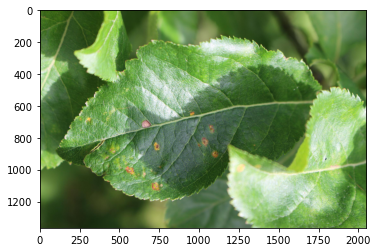

In [26]:
image1=Image.open(r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\Test_1.jpg')
plt.imshow(image1)
plt.show()

# Prepare the Training dataset


In [27]:
class_names=train.loc[:,'healthy':].columns             #extracting the column names 
print(class_names)

Index(['healthy', 'multiple_diseases', 'rust', 'scab'], dtype='object')


In [28]:
number=0
train['label']=0     #making new column as label
for i in class_names:
    train['label']=train['label'] + train[i] * number       #if train label healthy =0 same asmore
    number=number+1

In [29]:
train.head()           #if just given train then we will be able to see that it will classify all the sets

,image_id,healthy,multiple_diseases,rust,scab,label
0,Train_0,0,0,0,1,3
1,Train_1,0,1,0,0,1
2,Train_2,1,0,0,0,0
3,Train_3,0,0,1,0,2
4,Train_4,1,0,0,0,0


In [30]:
DIR


'C:\\Users\\HP\\Downloads\\Plant leaf(sem6)\\images'

In [31]:
import natsort
natsort.natsorted(os.listdir(DIR))          #for making all the test cases in the chronological order

['Test_0.jpg',
 'Test_1.jpg',
 'Test_2.jpg',
 'Test_3.jpg',
 'Test_4.jpg',
 'Test_5.jpg',
 'Test_6.jpg',
 'Test_7.jpg',
 'Test_8.jpg',
 'Test_9.jpg',
 'Test_10.jpg',
 'Test_11.jpg',
 'Test_12.jpg',
 'Test_13.jpg',
 'Test_14.jpg',
 'Test_15.jpg',
 'Test_16.jpg',
 'Test_17.jpg',
 'Test_18.jpg',
 'Test_19.jpg',
 'Test_20.jpg',
 'Test_21.jpg',
 'Test_22.jpg',
 'Test_23.jpg',
 'Test_24.jpg',
 'Test_25.jpg',
 'Test_26.jpg',
 'Test_27.jpg',
 'Test_28.jpg',
 'Test_29.jpg',
 'Test_30.jpg',
 'Test_31.jpg',
 'Test_32.jpg',
 'Test_33.jpg',
 'Test_34.jpg',
 'Test_35.jpg',
 'Test_36.jpg',
 'Test_37.jpg',
 'Test_38.jpg',
 'Test_39.jpg',
 'Test_40.jpg',
 'Test_41.jpg',
 'Test_42.jpg',
 'Test_43.jpg',
 'Test_44.jpg',
 'Test_45.jpg',
 'Test_46.jpg',
 'Test_47.jpg',
 'Test_48.jpg',
 'Test_49.jpg',
 'Test_50.jpg',
 'Test_51.jpg',
 'Test_52.jpg',
 'Test_53.jpg',
 'Test_54.jpg',
 'Test_55.jpg',
 'Test_56.jpg',
 'Test_57.jpg',
 'Test_58.jpg',
 'Test_59.jpg',
 'Test_60.jpg',
 'Test_61.jpg',
 'Test_62.jpg',
 '

In [32]:
def get_label_img(img):
    if search("Train",img):
        img=img.split('.')[0]      #to split the name as test66 and .jpg  if we give index 0 it give test66
        label=train.loc[train['image_id']==img]['label']
        return label

In [33]:
import natsort
def create_train_data():
    images=natsort.natsorted(os.listdir(DIR))        
    for img in tqdm(images):
        label=get_label_img(img)
        path=os.path.join(DIR,img)
        
        if search("Train",img):
            if (img.split("_")[1].split(".")[0]) and label.item()==0:      
                shutil.copy(path,r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\train\healthy')
            
            elif(img.split("_")[1].split(".")[0]) and label.item()==1:
                shutil.copy(path,r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\train\multiple_diseases')
                
            elif(img.split("_")[1].split(".")[0]) and label.item()==2:
                shutil.copy(path,r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\train\rust')
                
            elif(img.split("_")[1].split(".")[0]) and label.item()==3:
                shutil.copy(path,r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\train\scab')
                
        elif search("Test",img):
            shutil.copy(path,r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\test')
                

In [34]:
shutil.os.mkdir(r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\train')
shutil.os.mkdir(r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\train\healthy')
shutil.os.mkdir(r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\train\multiple_diseases')
shutil.os.mkdir(r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\train\rust')
shutil.os.mkdir(r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\train\scab')

shutil.os.mkdir(r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\test')

In [35]:
train_dir = create_train_data()
#INORDER TO CLASSIFY ALL THE IMAGES OF TRAIN DATA TO DIFFERNT CATEGORIES 

100%|█████████████████████████████████████████████████████████████████████████████| 3644/3644 [00:10<00:00, 348.40it/s]


# NOW WE HAVE TO PROCESS OUR DATA 

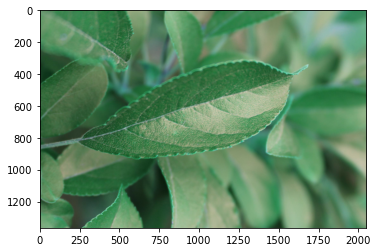

In [36]:
import cv2
Train_DIR=r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\train'    #INORDER TO REDUCE TO SIZE FOR BETTER CLARITY OF IMAGES
Categories=['healthy','multiple_disease','rust','scab']

for j in Categories:
    path=os.path.join(Train_DIR,j)          #JOINING THE TEST TO TRAIN TO PERFORM 
    for img in os.listdir(path):
        old=cv2.imread(os.path.join(path,img),cv2.COLOR_BGR2RGB) #INORDER TO GET SOME COLOR TO DETECT THE LEAF
        plt.imshow(old)
        plt.show()
        break
    break

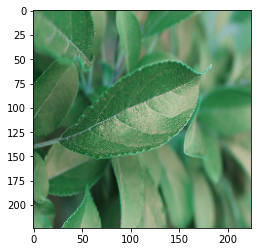

In [37]:
IMG_SIZE=224       #NOW WE WILL RESIZE THEM INORDER TO MAINTAIN ITS PIXEL FOR DETECTION
new_image=cv2.resize(old,(IMG_SIZE,IMG_SIZE))
plt.imshow(new_image)
plt.show()

# MODEL PREPERATION

In [38]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import ModelCheckpoint,EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense,Activation,Flatten, Conv2D, MaxPooling2D

In [39]:
IMG_SIZE=224 
datagen=ImageDataGenerator(rescale=1./255,               #to make all the images in particular range
                                shear_range=0.2,
                                zoom_range=0.2,
                                horizontal_flip=True,
                                vertical_flip=True,
                                validation_split=0.2)


train_datagen=datagen.flow_from_directory(r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\train',
                                         target_size=(IMG_SIZE,IMG_SIZE),
                                         batch_size=16,
                                         class_mode='categorical',
                                         subset='training')

val_datagen=datagen.flow_from_directory(r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\train',
                                         target_size=(IMG_SIZE,IMG_SIZE),
                                         batch_size=16,
                                         class_mode='categorical',
                                         subset='validation')

Found 1458 images belonging to 4 classes.
Found 363 images belonging to 4 classes.


## neural network making

In [40]:
IMG_SIZE=224 
model=Sequential()
model.add(Conv2D(64,(3,3),activation='relu',padding='same',input_shape=(IMG_SIZE,IMG_SIZE,3)))  #3 as we having rgb images 1 for grey image   also added padding was most important to make the size of image to 500 which we have mentioned above
model.add(MaxPooling2D(2,2))
model.add(Conv2D(64,(3,3),activation='relu',padding='same'))
model.add(MaxPooling2D(2,2))
model.add(Conv2D(64,(3,3),activation='relu',padding='same'))
model.add(MaxPooling2D(2,2))
model.add(Conv2D(128,(3,3),activation='relu',padding='same'))
model.add(MaxPooling2D(2,2))
model.add(Flatten())                                     #to see all the neurons (parts) clearly 
model.add(Dense(4,activation='softmax'))

# Compile the Model               making the model to realise the images and predict on the basis of that
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),  #we are choosing the adam optimiser as it is till best for view
    loss='categorical_crossentropy',
    metrics=['accuracy'])
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 224, 224, 64)      1792      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 112, 112, 64)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 112, 112, 64)      36928     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 56, 56, 64)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 56, 56, 64)        36928     
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 28, 28, 64)       0

In [41]:
checkpoint=ModelCheckpoint(r'C:\Users\HP\Downloads\images\models\plant detect2.h5',   #to save the best only of the data 
                          monitor='val_loss',
                          mode='min',
                          save_best_only=True,
                          verbose=1)
earlystop=EarlyStopping(monitor='val_loss',
                       min_delta=0,
                       patience=10,
                       verbose=1,
                       restore_best_weights=True)

callbacks=[checkpoint,earlystop]


In [42]:
model_history=model.fit_generator(train_datagen,validation_data=val_datagen,
                                 epochs=30,
                                 steps_per_epoch=train_datagen.samples//16,
                                 validation_steps=val_datagen.samples//16,
                                 callbacks=callbacks)

C:\Users\HP\AppData\Local\Temp/ipykernel_26996/1407545075.py:1: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  model_history=model.fit_generator(train_datagen,validation_data=val_datagen,


Epoch 1/30
91/91 [==============================] - ETA: 0s - loss: 1.2678 - accuracy: 0.3433
Epoch 1: val_loss improved from inf to 1.28165, saving model to C:\Users\HP\Downloads\images\models\plant detect2.h5
91/91 [==============================] - 193s 2s/step - loss: 1.2678 - accuracy: 0.3433 - val_loss: 1.2817 - val_accuracy: 0.3267
Epoch 2/30
91/91 [==============================] - ETA: 0s - loss: 1.2409 - accuracy: 0.3412
Epoch 2: val_loss improved from 1.28165 to 1.24579, saving model to C:\Users\HP\Downloads\images\models\plant detect2.h5
91/91 [==============================] - 182s 2s/step - loss: 1.2409 - accuracy: 0.3412 - val_loss: 1.2458 - val_accuracy: 0.3466
Epoch 3/30
91/91 [==============================] - ETA: 0s - loss: 1.2466 - accuracy: 0.3821
Epoch 3: val_loss improved from 1.24579 to 1.16121, saving model to C:\Users\HP\Downloads\images\models\plant detect2.h5
91/91 [==============================] - 147s 2s/step - loss: 1.2466 - accuracy: 0.3821 - val_loss:

Epoch 26/30
91/91 [==============================] - ETA: 0s - loss: 0.2405 - accuracy: 0.9209
Epoch 26: val_loss did not improve from 0.24522
91/91 [==============================] - 213s 2s/step - loss: 0.2405 - accuracy: 0.9209 - val_loss: 0.3079 - val_accuracy: 0.8977
Epoch 27/30
91/91 [==============================] - ETA: 0s - loss: 0.1873 - accuracy: 0.9348
Epoch 27: val_loss did not improve from 0.24522
91/91 [==============================] - 198s 2s/step - loss: 0.1873 - accuracy: 0.9348 - val_loss: 0.2481 - val_accuracy: 0.9205
Epoch 28/30
91/91 [==============================] - ETA: 0s - loss: 0.2761 - accuracy: 0.9036
Epoch 28: val_loss did not improve from 0.24522
91/91 [==============================] - 207s 2s/step - loss: 0.2761 - accuracy: 0.9036 - val_loss: 0.2937 - val_accuracy: 0.8949
Epoch 29/30
91/91 [==============================] - ETA: 0s - loss: 0.2294 - accuracy: 0.9293
Epoch 29: val_loss did not improve from 0.24522
91/91 [==============================]

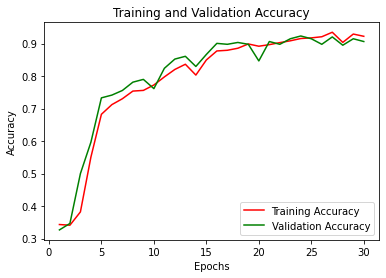

In [43]:
import matplotlib.pyplot as plt
acc_train=model_history.history['accuracy']                         #graphical representation of accuracy
acc_val=model_history.history['val_accuracy']
epochs=range(1,31)
plt.plot(epochs,acc_train,'r',label='Training Accuracy')
plt.plot(epochs,acc_val,'g',label='Validation Accuracy')
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np



In [68]:
# Assuming you have accuracy data stored in lists acc_train and acc_val
acc_train =model_history.history['accuracy']   # Training accuracy data
acc_val = model_history.history['val_accuracy']   # Validation accuracy data

# Create a dictionary with accuracy data
data = {
    'Epochs': list(range(1, len(acc_train) + 1)),
    'Training Accuracy': acc_train,
    'Validation Accuracy': acc_val
}




Our dataset is :  [[0.24461088 0.7032638  0.12528499 0.06764783 0.29019952 0.63042372
  0.7200237  0.59744574 0.07326177 0.0386405 ]
 [0.98058509 0.65792659 0.85044482 0.50722495 0.98918227 0.14710332
  0.1301923  0.82417672 0.2477489  0.6045774 ]
 [0.22301384 0.23550642 0.33835908 0.25347519 0.17818539 0.06063786
  0.97304596 0.65113057 0.94976372 0.47847076]
 [0.64734105 0.95273541 0.78719654 0.31468961 0.4237275  0.68460227
  0.93255145 0.59792059 0.16476502 0.40751617]
 [0.59767575 0.25544158 0.0872258  0.79306314 0.34305472 0.59639841
  0.6034818  0.435923   0.45072456 0.43656454]
 [0.81786755 0.37441009 0.63042016 0.6232496  0.56481798 0.31855142
  0.31660981 0.20174693 0.29060412 0.71370219]
 [0.48423672 0.20840799 0.77729526 0.01894149 0.39200198 0.80297274
  0.7975494  0.66920473 0.46591379 0.38268621]
 [0.73714569 0.66128667 0.86160329 0.7448458  0.42527323 0.34802045
  0.5598434  0.45200397 0.44930998 0.42371322]
 [0.59673005 0.45647677 0.63991679 0.85572125 0.73896221 0.977

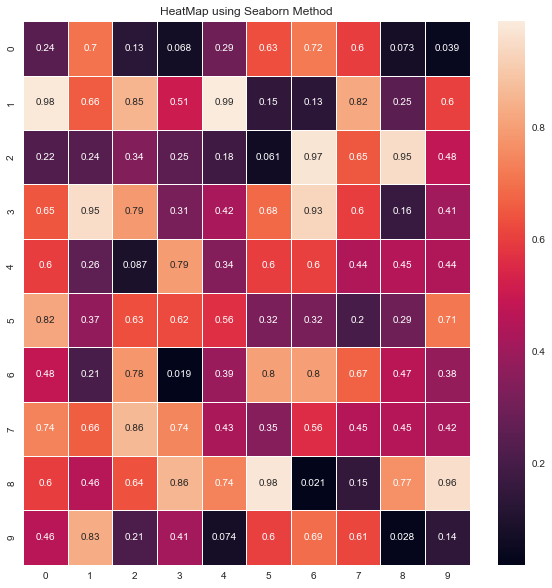

In [91]:
plt.style.use("seaborn")
 
# 2. Generate a 10x10 random integer matrix
data = np.random.rand(10,10)
print("Our dataset is : ",data)
 
# 3. Plot the heatmap
plt.figure(figsize=(10,10))
heat_map = sns.heatmap( data, linewidth = 1 , annot = True)
plt.title( "HeatMap using Seaborn Method" )
plt.show()

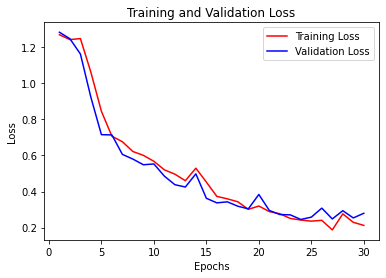

In [44]:
loss_train=model_history.history['loss']              #graphical representation of loss
loss_val=model_history.history['val_loss']
epochs=range(1,31)
plt.plot(epochs,loss_train,'r',label='Training Loss')
plt.plot(epochs,loss_val,'b',label='Validation Loss')
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


# # prediction of leaf for a single image


In [45]:
from PIL import Image
test_image=r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\Test_23.jpg'
image_result=Image.open(test_image)



In [46]:
from tensorflow.keras.preprocessing import image
test_image=image.load_img(test_image,target_size=(224,224))
test_image=image.img_to_array(test_image)
test_image=test_image/255
test_image=np.expand_dims(test_image,axis=0)              #converting to 4 dimension 
result=model.predict(test_image)
print(np.argmax(result))


3


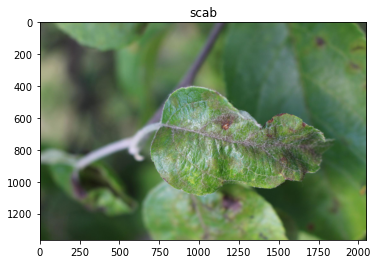

In [47]:
import numpy as np
Categories=['healthy','multiple_disease','rust','scab']
image_result=plt.imshow(image_result)
plt.title(Categories[np.argmax(result)])
plt.show()


# 2nd prediction


In [48]:
from PIL import Image
test_image=r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\Test_1.jpg'
image_result=Image.open(test_image)
from tensorflow.keras.preprocessing import image
test_image=image.load_img(test_image,target_size=(224,224))
test_image=image.img_to_array(test_image)
test_image=test_image/255
test_image=np.expand_dims(test_image,axis=0)              #converting to 4 dimension 
result=model.predict(test_image)
print(np.argmax(result))


2


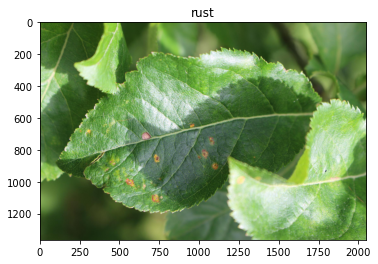

In [49]:
import numpy as np
Categories=['healthy','multiple_disease','rust','scab']
image_result=plt.imshow(image_result)
plt.title(Categories[np.argmax(result)])
plt.show()


# 3rd prediction


In [50]:
from PIL import Image
test_image=r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\Test_8.jpg'
image_result=Image.open(test_image)
from tensorflow.keras.preprocessing import image
test_image=image.load_img(test_image,target_size=(224,224))
test_image=image.img_to_array(test_image)
test_image=test_image/255
test_image=np.expand_dims(test_image,axis=0)              #converting to 4 dimension 
result=model.predict(test_image)
print(np.argmax(result))


3


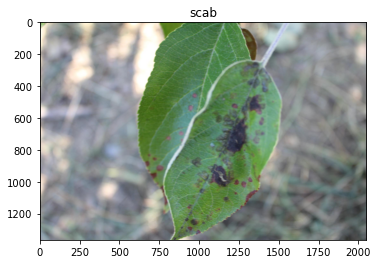

In [51]:
import numpy as np
Categories=['healthy','multiple_disease','rust','scab']
image_result=plt.imshow(image_result)
plt.title(Categories[np.argmax(result)])
plt.show()


# 4th predic

In [52]:
from PIL import Image
test_image=r'C:\Users\HP\Downloads\Plant leaf(sem6)\images\Test_3.jpg'
image_result=Image.open(test_image)
from tensorflow.keras.preprocessing import image
test_image=image.load_img(test_image,target_size=(224,224))
test_image=image.img_to_array(test_image)
test_image=test_image/255
test_image=np.expand_dims(test_image,axis=0)              #converting to 4 dimension 
result=model.predict(test_image)
print(np.argmax(result))


0


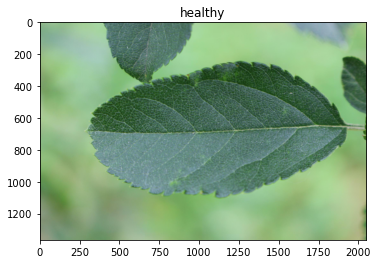

In [53]:
import numpy as np
Categories=['healthy','multiple_disease','rust','scab']
image_result=plt.imshow(image_result)
plt.title(Categories[np.argmax(result)])
plt.show()
